In [2]:
import ants
from pathlib import Path
import subprocess
import SimpleITK as sitk

In [3]:
ref_image = "/Users/igor.varha/CCP_workdir/ref_mouse/oriented_image.nii.gz"
ref_mask = "/Users/igor.varha/CCP_workdir/ref_mouse/oriented_mask.nii.gz"

flo_image = "/Users/igor.varha/CCP_workdir/working_mouse/ct_image.nii.gz"
flo_mask ="/Users/igor.varha/CCP_workdir/working_mouse/bone_coregistration_mask.nii.gz"

In [41]:
def flip_image(im_file_in: str, im_file_out: str, axis):
    """
    Flip an image along specified axes and preserve spatial alignment.

    Parameters:
        im_file_in (str): Path to the input image.
        im_file_out (str): Path to save the flipped image.
        axis (Tuple[bool, bool, bool]): Axes along which to flip (e.g., (True, False, False)).
    """
    if Path(im_file_out).exists():
        Path(im_file_out).unlink()

    # Read the input image
    image = sitk.ReadImage(im_file_in)

    # Flip the image
    flipped_image = sitk.Flip(image,axis)

    # Ensure spatial metadata (origin, spacing, direction) is consistent
    flipped_image.SetOrigin(image.GetOrigin())
    flipped_image.SetSpacing(image.GetSpacing())
    flipped_image.SetDirection(image.GetDirection())

    # Save the flipped image
    sitk.WriteImage(flipped_image,im_file_out)


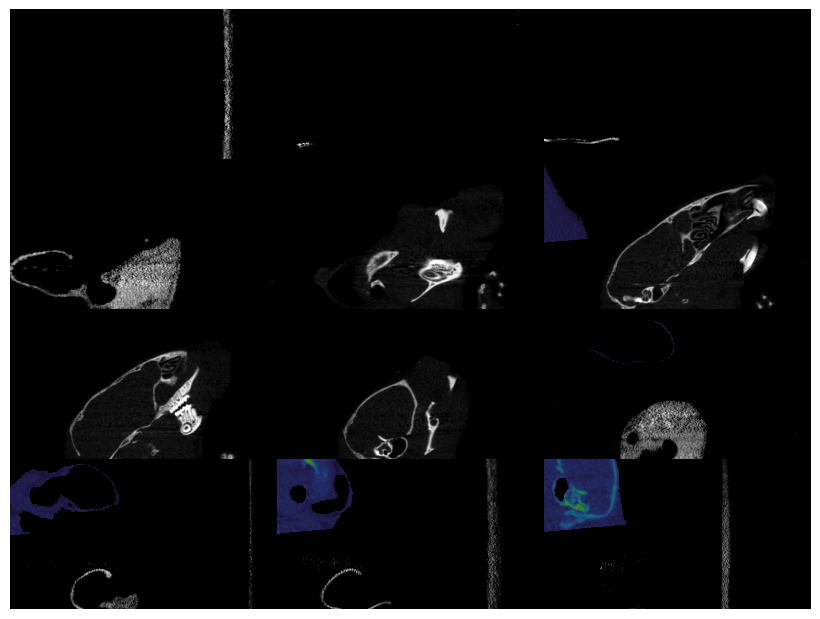

In [53]:

ref_im = ants.image_read(ref_image)
flo_im = ants.image_read(flo_image)
ref_m = ants.image_read(ref_mask)

def reorient_normal_image(image_orig :sitk.Image,label_orig:sitk.Image):
    label_shape_filter = sitk.LabelShapeStatisticsImageFilter()
    label_shape_filter.Execute(label_orig)

    image_result = sitk.Image(image_orig)
    direction = label_shape_filter.GetOrientedBoundingBoxDirection(1)
    direction = np.reshape(direction,(3,3))

    direction[:,0] = -1 * direction[:,0]
    print(direction.reshape(-1))
    image_result.SetDirection(direction.reshape(-1).tolist())
    # if get_frontal_voxels(label_orig) > get_frontal_voxels(label_orig,False):
    #     print(True)
    # return
    image_result.SetDirection(direction)
    image_result.SetOrigin(label_shape_filter.GetCentroid(1))

    return image_result

def flip_register_plot(ref_image,floating_image, ref_mask,mov_mask,axis):
    # Flip the reference image along the x-axis

    flp_str = "/Users/igor.varha/CCP_workdir/working_mouse/ct_flip_image.nii.gz"
    flip_image(floating_image, flp_str, axis)
    flp_ms_str = "/Users/igor.varha/CCP_workdir/working_mouse/bone_coregistration_mask_flip.nii.gz"
    flip_image(mov_mask, flp_ms_str, axis)
    # Read the flipped reference image

    refim = ants.image_read(ref_image)
    flpim = ants.image_read(flp_str)
    ref_mask1 = ants.image_read(ref_mask)
    mov_mask1 = ants.image_read(flp_ms_str)

    ants.plot(flpim, overlay=refim, overlay_alpha=0.5)
    # Register the flipped reference image to the floating image
    # reg = ants.registration(fixed=refim, moving=flpim, mask=ref_mask1, moving_mask=mov_mask1,type_of_transform="Rigid")
    #
    # reg = ants.registration(fixed=refim, moving=flpim, mask=ref_mask1, moving_mask=mov_mask1,type_of_transform="Affine", initial_transform=reg['fwdtransforms'])
    #
    #
    # #plot registered image vs ref
    # ants.plot(reg['warpedmovout'], overlay=refim, overlay_alpha=0.5)

flip_register_plot(ref_image, flo_image,ref_mask, flo_mask,(True,False ,True) )






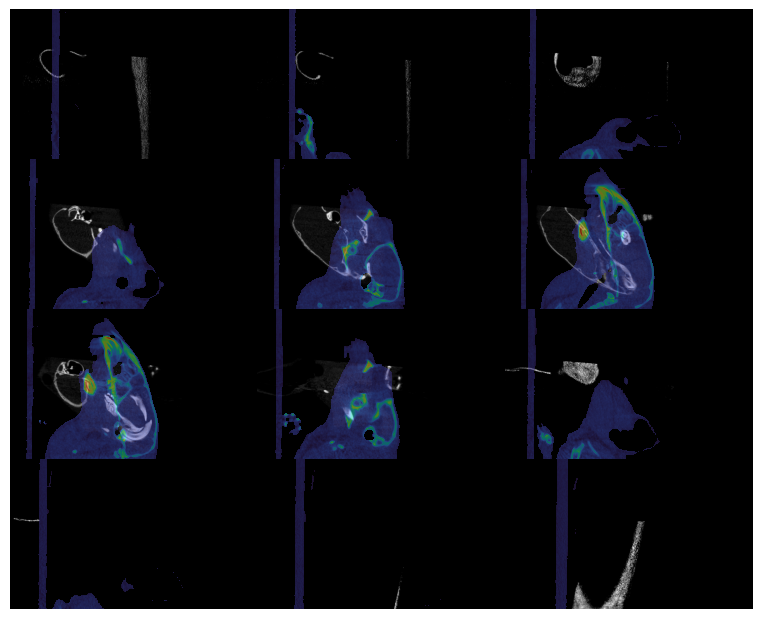

In [39]:
# plot the image



In [38]:
# write the image


ants.image_write(res['warpedmovout'], "/Users/igor.varha/CCP_workdir/working_mouse/ct_image_coreg.nii.gz")

In [40]:
from ants.core.ants_image import ANTsImage

def elastix( ref_file,flo_file, ref_mask, flo_mask, out_folder):
    elastix_parameters = "/Users/igor.varha/PycharmProjects/mouseSkullPipelines/models/affine.txt"

    cmd = f"source ~/.zshrc && elastix -f {ref_file} -m {flo_file}  -mMask {flo_mask} -p {elastix_parameters} -out {out_folder}"
    try:
        output = subprocess.check_output(cmd, shell=True, executable="/bin/zsh", stderr=subprocess.STDOUT)
        print(output)
        print(output.decode("utf-8"))

    except subprocess.CalledProcessError as e:
        print("Command failed with return code:", e.returncode)
        print("Command output:")
        print(e.output.decode("utf-8"))



def measure_coregistration_metric(image_path1, image_path2, metric="correlation"):
    """
    Measure coregistration metric between two images.

    Parameters:
        image_path1 (str): Path to the first image.
        image_path2 (str): Path to the second image.
        metric (str): Metric to evaluate. Options: "mutual_information", "correlation".

    Returns:
        float: Metric value representing similarity between the images.
    """
    # Load the images
    image1 = sitk.ReadImage(image_path1, sitk.sitkFloat32)
    image2 = sitk.ReadImage(image_path2, sitk.sitkFloat32)


    # Convert images to numpy arrays
    image1_array = sitk.GetArrayFromImage(image1)
    image2_array = sitk.GetArrayFromImage(image2)

    # Compute the metric
    if metric == "mutual_information":
        joint_histogram, _, _ = np.histogram2d(image1_array.ravel(), image2_array.ravel(), bins=32)
        joint_prob = joint_histogram / np.sum(joint_histogram)
        marginal_prob1 = np.sum(joint_prob, axis=0)
        marginal_prob2 = np.sum(joint_prob, axis=1)
        mutual_information = np.sum(
            joint_prob[joint_prob > 0] * np.log(joint_prob[joint_prob > 0] /
                                                (marginal_prob1[np.newaxis, :] *
                                                 marginal_prob2[:, np.newaxis])[joint_prob > 0]))
        return mutual_information

    elif metric == "correlation":
        correlation = np.corrcoef(image1_array.ravel(), image2_array.ravel())[0, 1]
        return correlation

    else:
        raise ValueError(f"Unsupported metric: {metric}")




In [36]:
# save image
out_folder = "/Users/igor.varha/CCP_workdir/working_mouse"

elastix(ref_image, flo_image, ref_mask, flo_mask, out_folder)


Command failed with return code: 1
Command output:

elastix is started at Fri Dec 20 11:00:48 2024.

which elastix:   elastix
  elastix version: 5.2.0
  Git revision SHA: ebb429a33bdf3248c2137fc4adb4259a2ec7db24
  Git revision date: Thu Jul 18 14:42:31 2024 +0200
  Build date: Jul 18 2024 13:00:42
  Compiler: Clang version Apple LLVM 14.0.0 (clang-1400.0.29.202)
  Compiler: GCC version Apple LLVM 14.0.0 (clang-1400.0.29.202)
  Memory address size: 64-bit
  CMake version: 3.24.2
  ITK version: 5.4.0

Command-line arguments: 
  -f /Users/igor.varha/CCP_workdir/ref_mouse/oriented_image.nii.gz -m /Users/igor.varha/CCP_workdir/working_mouse/ct_image.nii.gz -mMask /Users/igor.varha/CCP_workdir/working_mouse/bone_coregistration_mask.nii.gz -p /Users/igor.varha/PycharmProjects/mouseSkullPipelines/models/affine.txt -out /Users/igor.varha/CCP_workdir/working_mouse

elastix runs at: HONF39FXG24CR
  macOS 14.6.1 (x64), 23G93
  with 49152 MB memory, and 16 cores @ 2400 MHz.
------------------------

In [6]:
import os

In [8]:
os.environ

environ{'HOMEBREW_PREFIX': '/opt/homebrew',
        'CONDA_PROMPT_MODIFIER': '(mouseSkullPipelines) ',
        'COMMAND_MODE': 'unix2003',
        'INFOPATH': '/opt/homebrew/share/info:',
        'SHELL': '/bin/zsh',
        'PYTHONPATH': '/Users/igor.varha/PycharmProjects/mouseSkullPipelines:/Applications/PyCharm.app/Contents/plugins/python-ce/helpers/pydev:/Applications/PyCharm.app/Contents/plugins/python/helpers-pro/jupyter_debug',
        '__CFBundleIdentifier': 'com.jetbrains.pycharm',
        'TMPDIR': '/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/',
        'LC_ALL': 'en_US.UTF-8',
        'HOME': '/Users/igor.varha',
        'HOMEBREW_REPOSITORY': '/opt/homebrew',
        'PATH': '/opt/homebrew/opt/qt@5/bin:/Users/igor.varha/miniconda3/envs/mouseSkullPipelines/bin:/Users/igor.varha/miniconda3/condabin:/opt/homebrew/bin:/opt/homebrew/sbin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr

In [10]:
os.environ.get("DYLD_LIBRARY_PATH")

In [21]:
env = os.environ.copy()


In [22]:
env

{'HOMEBREW_PREFIX': '/opt/homebrew',
 'CONDA_PROMPT_MODIFIER': '(mouseSkullPipelines) ',
 'COMMAND_MODE': 'unix2003',
 'INFOPATH': '/opt/homebrew/share/info:',
 'SHELL': '/bin/zsh',
 'PYTHONPATH': '/Users/igor.varha/PycharmProjects/mouseSkullPipelines:/Applications/PyCharm.app/Contents/plugins/python-ce/helpers/pydev:/Applications/PyCharm.app/Contents/plugins/python/helpers-pro/jupyter_debug',
 '__CFBundleIdentifier': 'com.jetbrains.pycharm',
 'TMPDIR': '/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/',
 'LC_ALL': 'en_US.UTF-8',
 'HOME': '/Users/igor.varha',
 'HOMEBREW_REPOSITORY': '/opt/homebrew',
 'PATH': '/opt/homebrew/opt/qt@5/bin:/Users/igor.varha/miniconda3/envs/mouseSkullPipelines/bin:/Users/igor.varha/miniconda3/condabin:/opt/homebrew/bin:/opt/homebrew/sbin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/

In [1]:
import ants

In [8]:
file_mov= "/Users/igor.varha/Documents/oriented_image.nii.gz"
file_ref = "/Users/igor.varha/Documents/coregistered_head.nii.gz"

fixed = ants.image_read(file_ref)
moving = ants.image_read(file_mov)

# Запуск регистрации
reg = ants.registration(
    fixed=fixed,
    moving=moving,
    type_of_transform="SyNOnly",  # гибкая деформация, несимметричная
    grad_step=0.5,
    flow_sigma=1,
    total_sigma=0,
    reg_iterations=(200, 150, 100),
    verbose=True                # шаг градиента, можно уменьшить при рассыпании
)

# Получение результирующего изображения
warped = reg["warpedmovout"]
ants.image_write(warped, "warped_elastic.nii.gz")
print("Transform file already saved at:", reg["fwdtransforms"][0])
# Сохранение трансформаций
#ants.write_transform(reg["fwdtransforms"][0], "elastic_transform.nii.gz")


antsRegistration -d 3 -r [0x10591f0c8,0x13f08c4c8,1] -m mattes[0x10591f0c8,0x13f08c4c8,1,32] -t SyN[0.500000,1.000000,0.000000] -c [200x150x100,1e-7,8] -s 2x1x0 -f 4x2x1 -u 1 -z 1 -o [/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/tmpmn1jtzhe,0x105fe64a8,0x1400a5ec8] -x [NA,NA] --float 1 --write-composite-transform 0 -v 1
All_Command_lines_OK
Using single precision for computations.
The composite transform comprises the following transforms (in order): 
  1. Center of mass alignment using fixed image: 0x10591f0c8 and moving image: 0x13f08c4c8 (type = Euler3DTransform)
  Reading mask(s).
    Registration stage 0
      No fixed mask
      No moving mask
  number of levels = 3
  fixed image: 0x10591f0c8
  moving image: 0x13f08c4c8
Dimension = 3
Number of stages = 1
Use histogram matching = true
Winsorize image intensities = false
  Lower quantile = 0
  Upper quantile = 1


Stage 1 State
   Image metric = MattesMI
     Fixed image = Image (0x147fa5a10)
  RTTI typeinfo:   itk::Image<float

In [10]:
import shutil

shutil.copy(reg["fwdtransforms"][0],"elastic_transform.nii.gz")

'elastic_transform.nii.gz'

In [11]:
reg

{'warpedmovout': ANTsImage (LPI)
 	 Pixel Type : float (float32)
 	 Components : 1
 	 Dimensions : (241, 848, 492)
 	 Spacing    : (0.0516, 0.0516, 0.0516)
 	 Origin     : (0.0, 0.0, 0.0)
 	 Direction  : [-1.  0.  0.  0. -1.  0.  0.  0.  1.],
 'warpedfixout': ANTsImage (LPI)
 	 Pixel Type : float (float32)
 	 Components : 1
 	 Dimensions : (241, 848, 492)
 	 Spacing    : (0.0516, 0.0516, 0.0516)
 	 Origin     : (0.0, 0.0, 0.0)
 	 Direction  : [-1.  0.  0.  0. -1.  0.  0.  0.  1.],
 'fwdtransforms': ['/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/tmpmn1jtzhe1Warp.nii.gz',
  '/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/tmpmn1jtzhe0GenericAffine.mat'],
 'invtransforms': ['/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/tmpmn1jtzhe0GenericAffine.mat',
  '/var/folders/h4/q7bcqz290p5dmmm6t1r2t72r0000gp/T/tmpmn1jtzhe1InverseWarp.nii.gz']}